# Figure 1H - representative OFT spatial activity

This notebook follows the native-coordinate image construction in the original
analysis notebook. Each observed x-y coordinate receives its mean calcium
signal, unvisited pixels are assigned a low background value, and the image is
smoothed with a two-pixel Gaussian filter. The resulting image is normalized
from 0 to 1 within each example animal. The displayed blue–white–yellow
palette follows the accepted panel. This is a reconstruction from the
deposited coordinate table; the exact final example provenance and original
color-map definition were not preserved in the submitted analysis record.

**Input:** `data/source_data/figure_01/fig_1h_spatial_activity.csv`  
**Output:** `results/figures/Fig_1H.png`

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utilities import (
    ensure_directory,
    native_spatial_activity_image,
    project_path,
    save_figure,
)

OUTPUT_DIR = ensure_directory(project_path("results", "figures", root=REPO_ROOT))

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
source_path = project_path(
    "data", "source_data", "figure_01", "fig_1h_spatial_activity.csv", root=REPO_ROOT
)
spatial = pd.read_csv(source_path)
required = {"mouse_id", "genotype", "x", "y", "mean_dff"}
missing = required.difference(spatial.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")
if spatial["mouse_id"].nunique() != 2 or set(spatial["genotype"]) != {"WT", "RTT"}:
    raise ValueError("Figure 1H requires one WT and one RTT example.")
spatial.groupby(["genotype", "mouse_id"], observed=True).size().rename("coordinate_rows")

genotype  mouse_id  
RTT       NC303_RTT    5807
WT        NC139_WT      5970
Name: coordinate_rows, dtype: int64

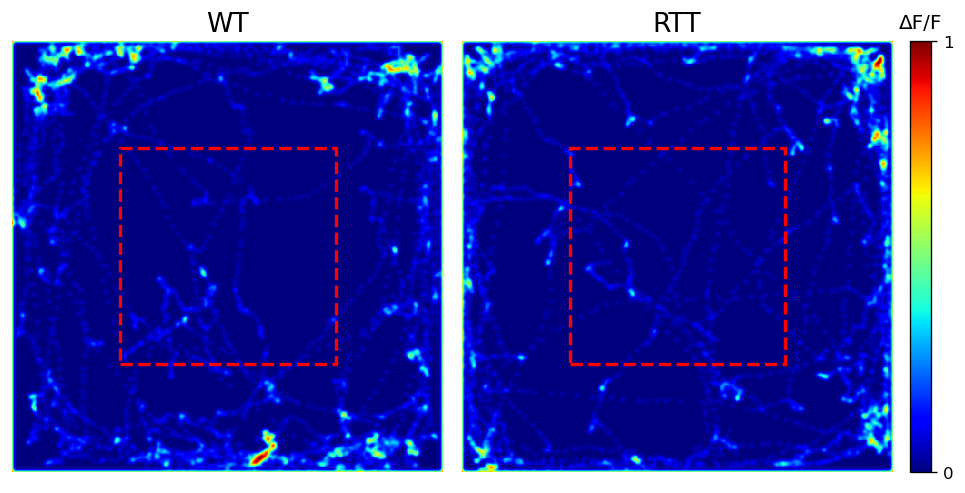

/Users/xiaoqiansun/Desktop/CellReports/results/figures/Fig_1H.png


In [4]:

fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
image_artist = None

for ax, genotype in zip(axes, ["WT", "RTT"]):
    example = spatial.loc[spatial["genotype"].eq(genotype)].copy()
    activity_image = native_spatial_activity_image(
        example,
        x_column="x",
        y_column="y",
        value_column="mean_dff",
        sigma=2,
        normalize=True,
    )
    image_artist = ax.imshow(
        activity_image,
        cmap='jet',
        vmin=0,
        vmax=1,
        origin="lower",
        interpolation="nearest",
        aspect="equal",
    )
    height, width = activity_image.shape
    ax.add_patch(
        mpl.patches.Rectangle(
            (width * 0.25, height * 0.25),
            width * 0.50,
            height * 0.50,
            fill=False,
            edgecolor="red",
            linewidth=2,
            linestyle="--",
        )
    )
    ax.set_title(genotype, fontsize=16)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

colorbar = fig.colorbar(image_artist, ax=axes, fraction=0.025, pad=0.02, ticks=[0, 1])
colorbar.ax.set_title("ΔF/F", pad=8)

png_path = save_figure(fig, OUTPUT_DIR / "Fig_1H.png")
plt.show()
print(png_path)